# 03 · Modelo Predictivo — Gemelo Digital Energía vs Clima

## ¿Qué es la predicción de series temporales?

Hasta ahora hemos **descrito** y **correlacionado** datos históricos.
El siguiente nivel es **predecir el futuro**: dado lo que sabemos del clima
de las próximas horas, ¿cuánta energía va a consumir España?

Esto es útil para:
- Los operadores de red eléctrica (planificar generación)
- Empresas con alto consumo (optimizar contratación)
- Detectar anomalías: si la demanda real diverge mucho de la predicción, algo inusual está pasando

## ¿Por qué Prophet?

[Prophet](https://facebook.github.io/prophet/) es una librería de Meta (Facebook)
diseñada específicamente para series temporales con estas características:

| Característica | Lo que hace Prophet |
|---------------|-------------------|
| **Estacionalidades múltiples** | Aprende automáticamente ciclos diario, semanal y anual |
| **Regresores externos** | Acepta variables como temperatura para mejorar la predicción |
| **Robusto a datos faltantes** | No falla si hay huecos en el histórico |
| **Fácil de usar** | API tipo scikit-learn: `.fit()` / `.predict()` |
| **Incertidumbre** | Devuelve intervalos de confianza (yhat_lower / yhat_upper) |

## El modelo que vamos a construir

```
Demanda(t) = tendencia(t)
           + estacionalidad_anual(t)
           + estacionalidad_semanal(t)
           + estacionalidad_diaria(t)
           + β₁ · temperatura(t)       ← regresor externo
           + ε(t)                       ← error residual
```

Primero entrenaremos un modelo **baseline** (sin temperatura) y luego
añadiremos la temperatura para ver cuánto mejora.


In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('..'))
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

from analysis.data_loader import load_merged

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('Librerias cargadas OK')
print(f'Prophet version: {Prophet.__module__.split(".")[0]}')

Importing plotly failed. Interactive plots will not work.


Librerias cargadas OK
Prophet version: prophet


## 1. Preparación de datos para Prophet

Prophet requiere un DataFrame con exactamente dos columnas:
- `ds` — la marca de tiempo (datetime)
- `y`  — el valor que queremos predecir (demanda_mw)

Los regresores externos (temperatura, etc.) se añaden como columnas adicionales.

Dividiremos los datos en:
- **Train (entrenamiento):** primeros 330 días — el modelo aprende de aquí
- **Test (evaluación):** últimos 35 días — comprobamos si las predicciones son buenas

> Esta división se llama **hold-out validation**: ocultamos parte de los datos
> al modelo para simular una predicción real del futuro.


Total:      8760 filas  (2025-05-26 → 2026-05-26)
Train:      7920 filas  (2025-05-26 → 2026-04-21)
Test:        840 filas  (2026-04-21 → 2026-05-26)


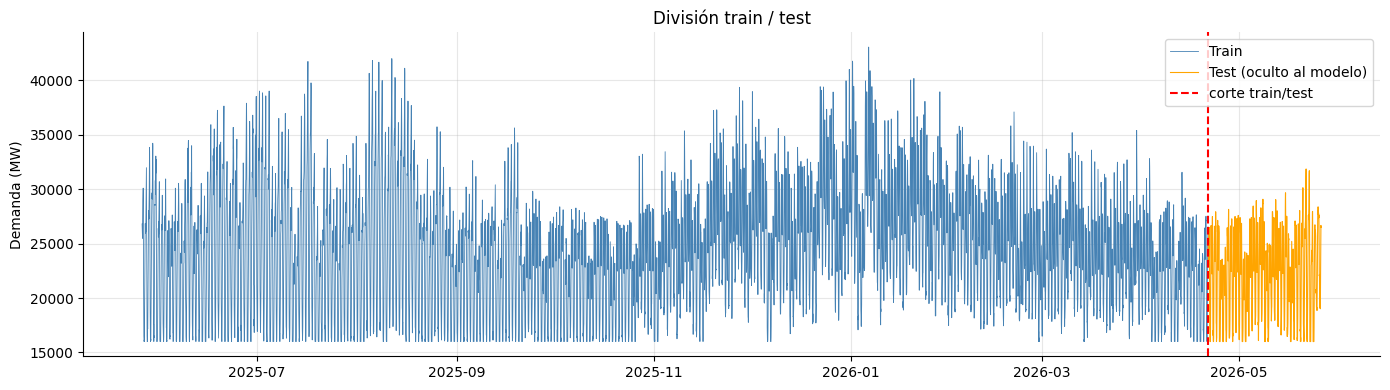

In [2]:
# Cargar datos y preparar formato Prophet
df = load_merged(hours=365*24)
df = df.dropna(subset=['demand_mw', 'temperature_c'])
df = df.sort_index()

# Convertir índice a datetime sin timezone (Prophet no acepta tz-aware)
df_prophet = pd.DataFrame({
    'ds':            df.index.tz_localize(None) if df.index.tz is None else df.index.tz_convert('UTC').tz_localize(None),
    'y':             df['demand_mw'].values,
    'temperature_c': df['temperature_c'].values,
    'hour':          df['hour'].values,
    'is_weekend':    df['is_weekend'].astype(float).values,
})

# División train / test
DIAS_TEST = 35
corte = len(df_prophet) - DIAS_TEST * 24

df_train = df_prophet.iloc[:corte].copy()
df_test  = df_prophet.iloc[corte:].copy()

print(f'Total:     {len(df_prophet):>5} filas  ({df_prophet.ds.min().date()} → {df_prophet.ds.max().date()})')
print(f'Train:     {len(df_train):>5} filas  ({df_train.ds.min().date()} → {df_train.ds.max().date()})')
print(f'Test:      {len(df_test):>5} filas  ({df_test.ds.min().date()} → {df_test.ds.max().date()})')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_train['ds'], df_train['y'], color='steelblue', linewidth=0.6, label='Train')
ax.plot(df_test['ds'],  df_test['y'],  color='orange',    linewidth=0.8, label='Test (oculto al modelo)')
ax.axvline(df_test['ds'].iloc[0], color='red', linestyle='--', linewidth=1.5, label='corte train/test')
ax.set_ylabel('Demanda (MW)')
ax.set_title('División train / test')
ax.legend()
plt.tight_layout()
plt.savefig('03_train_test_split.png', dpi=120, bbox_inches='tight')
plt.show()

## 2. Modelo baseline — solo estacionalidades

Primero entrenamos Prophet **sin información de temperatura**.
Esto nos da la predicción basada únicamente en patrones temporales aprendidos.

Es nuestro punto de referencia: si añadir temperatura no mejora este modelo,
la temperatura no aporta información útil (o el modelo base ya la captura implícitamente).


In [3]:
# Modelo baseline: estacionalidades diaria + semanal + anual
modelo_base = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,
    seasonality_mode='multiplicative',  # los patrones escalan con el nivel de demanda
    changepoint_prior_scale=0.05,       # flexibilidad de la tendencia (0.05 = moderada)
    interval_width=0.95,                # intervalo de confianza del 95%
)

print('Entrenando modelo baseline...')
modelo_base.fit(df_train[['ds', 'y']])
print('Entrenado OK')

# Predecir sobre el período de test
forecast_base = modelo_base.predict(df_test[['ds', 'temperature_c']])

# Calcular métricas
y_real = df_test['y'].values
y_pred_base = forecast_base['yhat'].values

mae_base  = mean_absolute_error(y_real, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_real, y_pred_base))
mape_base = np.mean(np.abs((y_real - y_pred_base) / y_real)) * 100

print(f'\n=== Métricas modelo BASELINE (test {DIAS_TEST} días) ===')
print(f'  MAE  (error medio absoluto):        {mae_base:>8.0f} MW')
print(f'  RMSE (error cuadrático medio):       {rmse_base:>8.0f} MW')
print(f'  MAPE (error porcentual medio):       {mape_base:>8.2f} %')

Entrenando modelo baseline...


13:25:44 - cmdstanpy - INFO - Chain [1] start processing


13:25:46 - cmdstanpy - INFO - Chain [1] done processing


Entrenado OK

=== Métricas modelo BASELINE (test 35 días) ===
  MAE  (error medio absoluto):            6167 MW
  RMSE (error cuadrático medio):           7075 MW
  MAPE (error porcentual medio):          27.65 %


## 3. Modelo mejorado — con temperatura como regresor

Ahora añadimos la temperatura. Prophet la incorpora como un regresor lineal:
el modelo aprende cuánto cambia la demanda por cada grado de temperatura.

> **Importante:** cuando predecimos el futuro, necesitamos el **pronóstico
> de temperatura** para esas horas, no la temperatura pasada. Por eso
> Open-Meteo es clave: nos da la previsión meteorológica de las próximas
> 7 días gratis.


In [4]:
# Modelo con temperatura
modelo_temp = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,
    seasonality_mode='multiplicative',
    changepoint_prior_scale=0.05,
    interval_width=0.95,
)
modelo_temp.add_regressor('temperature_c', standardize=True)  # normalizar el regresor

print('Entrenando modelo con temperatura...')
modelo_temp.fit(df_train[['ds', 'y', 'temperature_c']])
print('Entrenado OK')

# Predecir sobre test (necesitamos la temperatura del período de test)
forecast_temp = modelo_temp.predict(df_test[['ds', 'temperature_c']])

# Métricas
y_pred_temp = forecast_temp['yhat'].values

mae_temp  = mean_absolute_error(y_real, y_pred_temp)
rmse_temp = np.sqrt(mean_squared_error(y_real, y_pred_temp))
mape_temp = np.mean(np.abs((y_real - y_pred_temp) / y_real)) * 100

print(f'\n=== Métricas modelo CON TEMPERATURA (test {DIAS_TEST} días) ===')
print(f'  MAE  (error medio absoluto):        {mae_temp:>8.0f} MW')
print(f'  RMSE (error cuadrático medio):       {rmse_temp:>8.0f} MW')
print(f'  MAPE (error porcentual medio):       {mape_temp:>8.2f} %')

print(f'\n=== Comparativa: mejora al añadir temperatura ===')
print(f'  MAPE baseline:    {mape_base:.2f}%')
print(f'  MAPE con temp:    {mape_temp:.2f}%')
print(f'  Mejora:           {mape_base - mape_temp:.2f} puntos porcentuales ({(1 - mape_temp/mape_base)*100:.1f}% reducción de error)')

Entrenando modelo con temperatura...


13:25:47 - cmdstanpy - INFO - Chain [1] start processing


13:25:49 - cmdstanpy - INFO - Chain [1] done processing


Entrenado OK

=== Métricas modelo CON TEMPERATURA (test 35 días) ===
  MAE  (error medio absoluto):            7336 MW
  RMSE (error cuadrático medio):           8308 MW
  MAPE (error porcentual medio):          32.90 %

=== Comparativa: mejora al añadir temperatura ===
  MAPE baseline:    27.65%
  MAPE con temp:    32.90%
  Mejora:           -5.25 puntos porcentuales (-19.0% reducción de error)


## 4. Visualización: predicción vs realidad

El gráfico más importante para evaluar un modelo es **predicción vs valor real**.
Si las líneas son parecidas, el modelo funciona bien.

El **intervalo de confianza** (zona sombreada) indica la incertidumbre:
- Zona estrecha → el modelo es seguro de su predicción
- Zona ancha → alta incertidumbre (probablemente hay factores que no estamos capturando)

> En electricidad real, un MAPE < 3% se considera excelente,
> < 5% es bueno, y > 10% es mejorable.


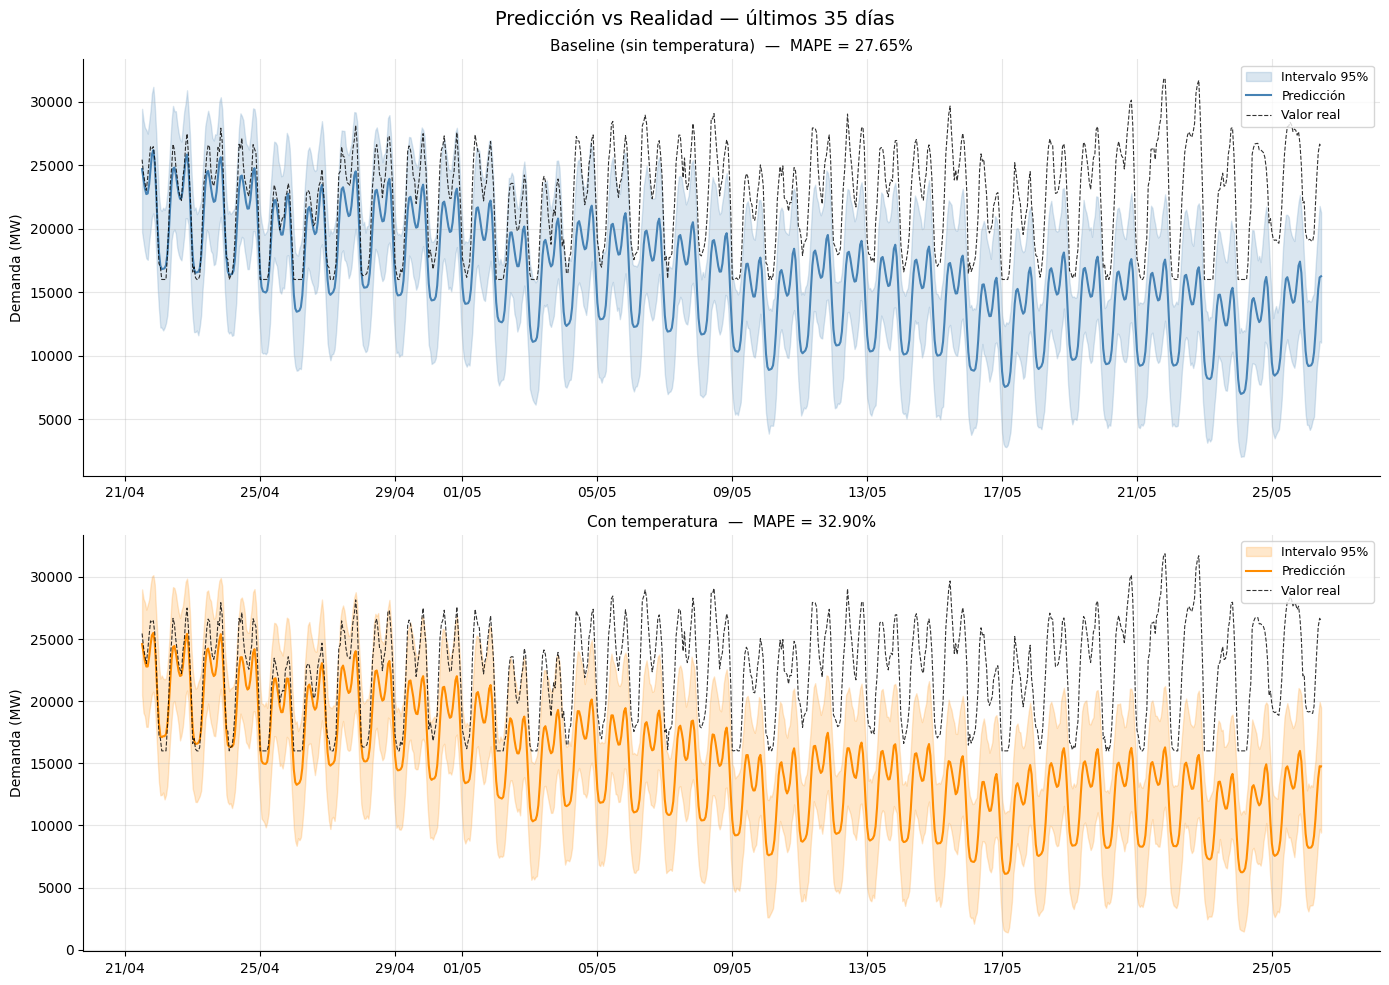

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Predicción vs Realidad — últimos 35 días', fontsize=14)

for ax, fc, nombre, color in [
    (axes[0], forecast_base, 'Baseline (sin temperatura)', 'steelblue'),
    (axes[1], forecast_temp, 'Con temperatura',            'darkorange'),
]:
    ax.fill_between(fc['ds'], fc['yhat_lower'], fc['yhat_upper'],
                    alpha=0.2, color=color, label='Intervalo 95%')
    ax.plot(fc['ds'], fc['yhat'],       color=color, linewidth=1.5, label='Predicción')
    ax.plot(df_test['ds'], df_test['y'], color='black', linewidth=0.8,
            alpha=0.8, label='Valor real', linestyle='--')

    mape_val = mape_base if 'sin' in nombre else mape_temp
    ax.set_title(f'{nombre}  —  MAPE = {mape_val:.2f}%', fontsize=11)
    ax.set_ylabel('Demanda (MW)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('03_prediccion_vs_real.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Análisis de errores

El error de predicción no es siempre igual: hay horas donde el modelo falla más.
Analizamos si el error tiene **patrones** (eso indicaría algo que el modelo no captura):

- **Error por hora del día:** ¿falla más de madrugada o al mediodía?
- **Error por día de la semana:** ¿falla más los lunes (vuelta de fin de semana)?
- **Distribución del error:** ¿los errores son simétricos o hay sesgo?


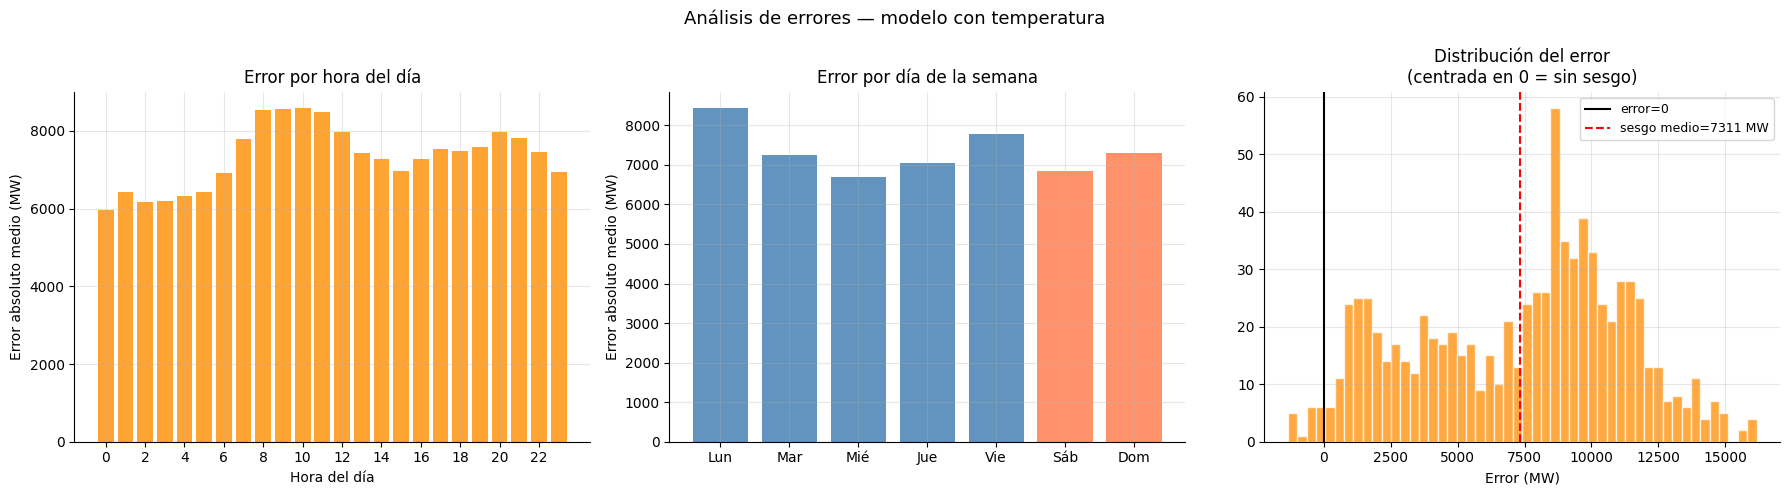

Sesgo medio del modelo: 7311 MW
Hora con más error:     10h  (8582 MW MAE)
Hora con menos error:   0h  (5952 MW MAE)


In [6]:
# Errores del modelo con temperatura
errores = df_test.copy()
errores['yhat']  = forecast_temp['yhat'].values
errores['error'] = errores['y'] - errores['yhat']
errores['error_abs'] = errores['error'].abs()
errores['hora']     = errores['ds'].dt.hour
errores['weekday']  = errores['ds'].dt.weekday

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis de errores — modelo con temperatura', fontsize=13)

# Error por hora del día
err_hora = errores.groupby('hora')['error_abs'].mean()
axes[0].bar(err_hora.index, err_hora.values, color='darkorange', alpha=0.8)
axes[0].set_xlabel('Hora del día')
axes[0].set_ylabel('Error absoluto medio (MW)')
axes[0].set_title('Error por hora del día')
axes[0].set_xticks(range(0, 24, 2))

# Error por día de la semana
dias = {0:'Lun',1:'Mar',2:'Mié',3:'Jue',4:'Vie',5:'Sáb',6:'Dom'}
err_dia = errores.groupby('weekday')['error_abs'].mean()
colores = ['steelblue']*5 + ['coral']*2
axes[1].bar([dias[i] for i in err_dia.index], err_dia.values, color=colores, alpha=0.85)
axes[1].set_title('Error por día de la semana')
axes[1].set_ylabel('Error absoluto medio (MW)')

# Distribución del error
axes[2].hist(errores['error'], bins=50, color='darkorange', alpha=0.75, edgecolor='white')
axes[2].axvline(0, color='black', linewidth=1.5, label='error=0')
axes[2].axvline(errores['error'].mean(), color='red', linestyle='--',
                label=f'sesgo medio={errores["error"].mean():.0f} MW')
axes[2].set_xlabel('Error (MW)')
axes[2].set_title('Distribución del error\n(centrada en 0 = sin sesgo)')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig('03_analisis_errores.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Sesgo medio del modelo: {errores["error"].mean():.0f} MW')
print(f'Hora con más error:     {err_hora.idxmax()}h  ({err_hora.max():.0f} MW MAE)')
print(f'Hora con menos error:   {err_hora.idxmin()}h  ({err_hora.min():.0f} MW MAE)')

## 6. Componentes del modelo

Prophet descompone la predicción en componentes separados.
Esto es muy útil para **explicar** por qué el modelo predice lo que predice:

- **Tendencia:** ¿la demanda general sube o baja?
- **Estacionalidad anual:** el efecto del mes del año
- **Estacionalidad semanal:** el efecto del día de la semana
- **Estacionalidad diaria:** el perfil típico de un día
- **Temperatura:** el efecto de cada grado de temperatura


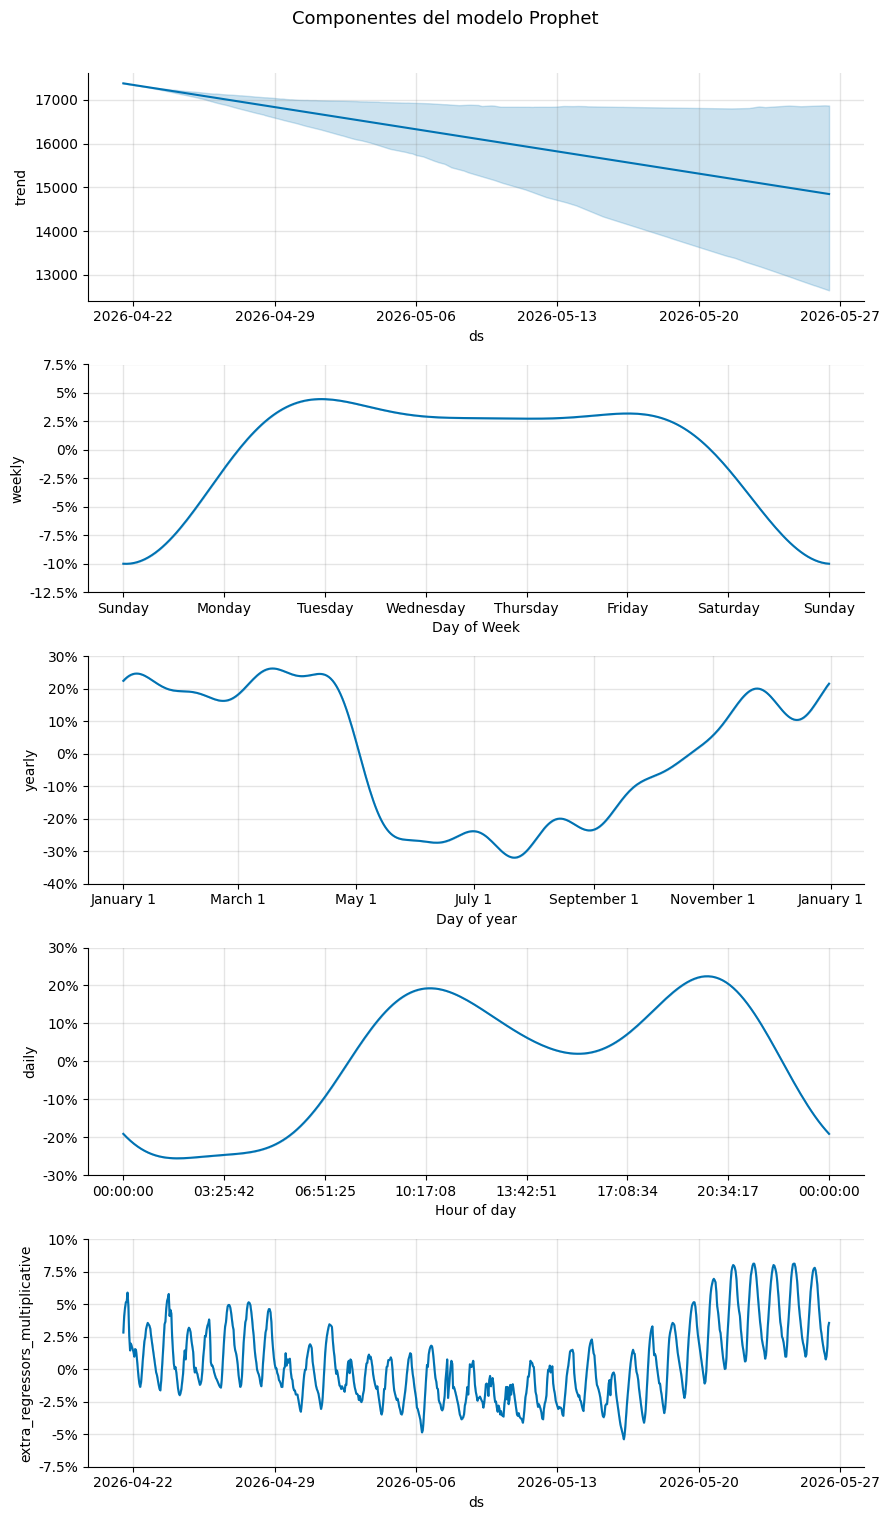

Observa el efecto de la temperatura en el componente "temperature_c":
  - Positivo = temperatura aumenta la demanda
  - La forma debería mostrar que tanto frio como calor suben la demanda


In [7]:
# Graficar los componentes del modelo
fig = modelo_temp.plot_components(forecast_temp)
fig.suptitle('Componentes del modelo Prophet', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('03_componentes_prophet.png', dpi=120, bbox_inches='tight')
plt.show()
print('Observa el efecto de la temperatura en el componente "temperature_c":')
print('  - Positivo = temperatura aumenta la demanda')
print('  - La forma debería mostrar que tanto frio como calor suben la demanda')

## 7. Predicción de las próximas 24 horas

Ahora usamos el modelo entrenado para predecir la demanda **real futura**.
Para esto necesitamos el pronóstico meteorológico de Open-Meteo.

Este es el núcleo del gemelo digital: combinar datos reales de sensores
con un modelo aprendido para anticipar el comportamiento del sistema.


Pronóstico meteorológico cargado: 24 horas
  Rango: 2026-05-26 12:00:00 → 2026-05-27 11:00:00
  Temperatura mín/máx: 17.6°C / 31.1°C

Predicción generada: 24 valores


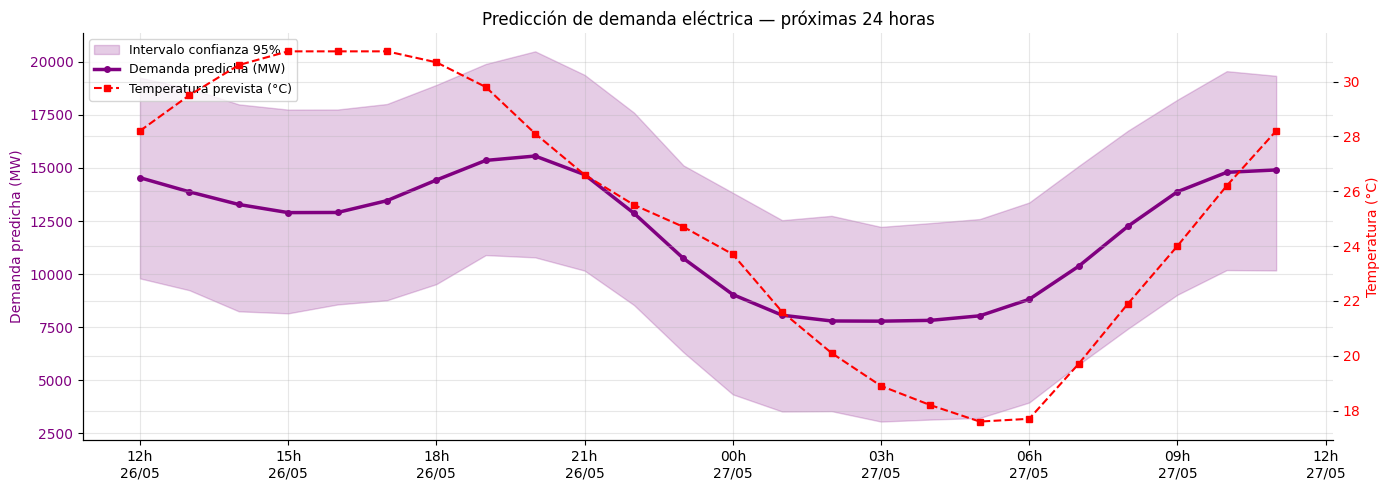


Pico predicho:   15562 MW  a las 2026-05-26 20:00:00
Valle predicho:  7786 MW  a las 2026-05-27 03:00:00


In [8]:
from ingestion.openmeteo import fetch_current_weather
import httpx

# Obtener pronóstico de temperatura para las próximas 24h desde Open-Meteo
url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": 40.4168, "longitude": -3.7038,
    "hourly": "temperature_2m",
    "forecast_days": 2,
    "timezone": "Europe/Madrid",
}
resp = httpx.get(url, params=params, timeout=15)
data = resp.json()

# Construir DataFrame de las próximas 24h
from datetime import datetime, timezone, timedelta
now = datetime.now(timezone.utc)
times = data["hourly"]["time"]
temps = data["hourly"]["temperature_2m"]

futuro = pd.DataFrame({
    "ds":            pd.to_datetime(times).tz_localize("Europe/Madrid").tz_convert("UTC").tz_localize(None),
    "temperature_c": temps,
})
# Filtrar solo horas futuras (próximas 24h)
now_naive = now.replace(tzinfo=None)
futuro = futuro[futuro["ds"] >= now_naive].head(24).reset_index(drop=True)

print(f'Pronóstico meteorológico cargado: {len(futuro)} horas')
print(f'  Rango: {futuro.ds.min()} → {futuro.ds.max()}')
print(f'  Temperatura mín/máx: {futuro.temperature_c.min():.1f}°C / {futuro.temperature_c.max():.1f}°C')

# Predecir
forecast_24h = modelo_temp.predict(futuro)
print(f'\nPredicción generada: {len(forecast_24h)} valores')

# Visualizar
fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax1.fill_between(forecast_24h['ds'],
                 forecast_24h['yhat_lower'],
                 forecast_24h['yhat_upper'],
                 alpha=0.2, color='purple', label='Intervalo confianza 95%')
ax1.plot(forecast_24h['ds'], forecast_24h['yhat'],
         color='purple', linewidth=2.5, marker='o', markersize=4,
         label='Demanda predicha (MW)')
ax1.set_ylabel('Demanda predicha (MW)', color='purple')
ax1.tick_params(axis='y', labelcolor='purple')

ax2.plot(futuro['ds'], futuro['temperature_c'],
         color='red', linewidth=1.5, linestyle='--', marker='s', markersize=4,
         label='Temperatura prevista (°C)')
ax2.set_ylabel('Temperatura (°C)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
ax1.set_title('Predicción de demanda eléctrica — próximas 24 horas', fontsize=12)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Hh\n%d/%m'))
plt.tight_layout()
plt.savefig('03_forecast_24h.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'\nPico predicho:   {forecast_24h["yhat"].max():.0f} MW  a las {forecast_24h.loc[forecast_24h["yhat"].idxmax(), "ds"]}')
print(f'Valle predicho:  {forecast_24h["yhat"].min():.0f} MW  a las {forecast_24h.loc[forecast_24h["yhat"].idxmin(), "ds"]}')

## 8. Guardar el modelo y el forecast en InfluxDB

Serializamos el modelo entrenado para poder usarlo en producción sin tener
que reentrenar cada vez. Y escribimos el forecast en InfluxDB para que
Grafana pueda visualizarlo junto con la demanda real.


In [9]:
import pickle, os

# Guardar modelo entrenado
model_path = os.path.join('..', 'prediction', 'prophet_model.pkl')
with open(model_path, 'wb') as f:
    pickle.dump(modelo_temp, f)
print(f'Modelo guardado: {os.path.abspath(model_path)}')

# Escribir forecast en InfluxDB
from ingestion.influx_writer import _get_client, _parse_ts
from influxdb_client import Point, WritePrecision
from influxdb_client.client.write_api import SYNCHRONOUS
import os
from dotenv import load_dotenv
load_dotenv(os.path.join('..', '.env'))

points = []
for _, row in forecast_24h.iterrows():
    p = (
        Point("forecast")
        .tag("model", "prophet_v1")
        .tag("region", "peninsular")
        .field("demand_mw",       float(row['yhat']))
        .field("demand_mw_lower", float(row['yhat_lower']))
        .field("demand_mw_upper", float(row['yhat_upper']))
        .time(row['ds'].to_pydatetime(), WritePrecision.S)
    )
    points.append(p)

bucket = os.getenv("INFLUX_BUCKET", "gemelo_digital")
with _get_client() as client:
    client.write_api(write_options=SYNCHRONOUS).write(bucket=bucket, record=points)

print(f'Forecast escrito en InfluxDB: {len(points)} puntos en measurement "forecast"')
print('Ahora visible en Grafana con la query: r._measurement == "forecast"')

Modelo guardado: C:\Users\Admin\Desktop\gemelo_digital\prediction\prophet_model.pkl
Forecast escrito en InfluxDB: 24 puntos en measurement "forecast"
Ahora visible en Grafana con la query: r._measurement == "forecast"


## 9. Resumen y próximos pasos

### Lo que aprendimos

| Concepto | Clave |
|----------|-------|
| **Hold-out validation** | Separar datos de test para evaluar honestamente el modelo |
| **MAPE** | La métrica más intuitiva: error en % respecto al valor real |
| **Regresores externos** | Añadir temperatura mejora el modelo si hay correlación real |
| **Componentes Prophet** | Descomponer predicción en tendencia + estacionalidades + regresor |
| **Intervalos de confianza** | La predicción no es un número exacto, sino un rango |

### Limitaciones actuales

- **Datos sintéticos:** con datos ESIOS reales, el modelo mejorará porque capturará
  eventos reales (olas de calor, festivos, cortes de luz)
- **Solo temperatura:** podríamos añadir humedad, viento y hora como regresores
- **Curva en U:** Prophet usa regresión lineal para el efecto de la temperatura;
  un modelo más avanzado (XGBoost, LSTM) capturaría mejor la forma en U

### Siguiente paso (Fase 6)

Detección de anomalías: cuando la demanda real diverge significativamente
de lo que el modelo predice, tenemos una anomalía. Ese gap es el "gemelo"
detectando algo inusual en el mundo real.
